<a href="https://colab.research.google.com/github/milindaM12/MSE-800/blob/main/student_business_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data analytics in action: Retail customer decisions

**Business brief:** You are a data analyst at a fictional online retailer. Management wants to forecast monthly customer spending, identify customers at risk of churn, understand churn drivers, and discover customer segments for marketing decisions.

All data are **synthetic** (generated in this notebook); no downloads or personal data. Outcomes are simulated and are not evidence of causal effects. Do not use this exercise to make decisions about real people.

**Learning goals:** frame business questions, avoid data leakage, train/test models, evaluate appropriate metrics, and recommend actions with limitations.


In [ ]:
# Import libraries for working with data, creating graphs, and building machine learning models.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import tools for splitting data into training and testing sets and evaluating models
# using cross-validation.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# A pipeline allows us to combine data preparation steps and a machine learning model.
from sklearn.pipeline import make_pipeline

# StandardScaler puts numerical features on a similar scale.
# This is especially important for distance-based models such as K-Nearest Neighbours.
from sklearn.preprocessing import StandardScaler

# LinearRegression predicts numerical values, such as customer spending.
from sklearn.linear_model import LinearRegression

# KNeighborsClassifier predicts a category based on nearby data points.
from sklearn.neighbors import KNeighborsClassifier

# DecisionTreeClassifier makes predictions using a series of decision rules.
# plot_tree allows us to visualise the decision tree.
from sklearn.tree import DecisionTreeClassifier, plot_tree

# KMeans groups similar data points into clusters without using target labels.
from sklearn.cluster import KMeans

# Import metrics to measure how well our models perform.
# Regression metrics evaluate numerical predictions.
# Classification metrics evaluate category predictions.
# ConfusionMatrixDisplay helps us visualise classification results.
# silhouette_score measures how well-separated clusters are.
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, recall_score, precision_score,
    confusion_matrix, ConfusionMatrixDisplay, silhouette_score
)


# --------------------------------------------------
# 1. Set up a random number generator
# --------------------------------------------------

# A fixed random seed makes the generated data reproducible.
# This means you should obtain the same dataset each time they run the code.
rng = np.random.default_rng(42)


# --------------------------------------------------
# 2. Choose the number of customers
# --------------------------------------------------

# We will create a synthetic dataset containing 800 customers.
# Synthetic data is artificially generated rather than collected from real people.
n = 800


# --------------------------------------------------
# 3. Generate customer behaviour data
# --------------------------------------------------

# Generate the number of visits made by each customer.
# A Poisson distribution is often used to model counts.
# We add 1 so that every customer has at least one visit.
visits = rng.poisson(9, n) + 1

# Generate the number of orders placed in the last month.
# The minimum function ensures that orders cannot exceed visits.
orders = np.minimum(visits, rng.poisson(3, n) + 1)

# Generate customer tenure: how many months each customer has been with the business.
# Values range from 1 to 60 months, inclusive.
tenure = rng.integers(1, 61, n)

# Generate the number of days since each customer's last order.
# Values range from 1 to 120 days, inclusive.
days_since = rng.integers(1, 121, n)

# Generate discount rates between 0 and 0.4 (0% to 40%).
# Each customer receives a randomly generated discount rate.
discount = rng.uniform(0, 0.4, n)

# Generate the number of customer support tickets.
# This is another count variable generated using a Poisson distribution.
support = rng.poisson(1.1, n)


# --------------------------------------------------
# 4. Generate the monthly spending target
# --------------------------------------------------

# Create a synthetic monthly spending value for each customer.
# Spending increases with the number of orders, visits, and months of tenure.
# Higher discounts reduce the spending value in this formula.
# Random noise is added to make the data more realistic.
#
# The formula is:
#   Base spending                  = 35
#   Contribution from orders       = 16 per order
#   Contribution from visits      = 2.2 per visit
#   Contribution from tenure      = 0.45 per month
#   Effect of discount            = -55 times the discount rate
#   Random variation              = normally distributed noise
#
# np.maximum ensures that spending is never below 15.
spend = np.maximum(
    15,
    35
    + 16 * orders
    + 2.2 * visits
    + 0.45 * tenure
    - 55 * discount
    + rng.normal(0, 28, n)
)


# --------------------------------------------------
# 5. Generate the probability of customer churn
# --------------------------------------------------

# Churn means that a customer stops using a business or service.
# First, calculate a score based on customer behaviour.
#
# In this example:
# - More days since the last order increase the churn score.
# - More support tickets increase the churn score.
# - More orders reduce the churn score.
# - Longer tenure reduces the churn score.
#
# These relationships are built into our synthetic data.
logit = (
    -2.5
    + 0.028 * days_since
    + 0.38 * support
    - 0.12 * orders
    - 0.012 * tenure
)

# Convert the score into a probability between 0 and 1.
# The logistic function is commonly used in binary classification.
prob = 1 / (1 + np.exp(-logit))

# Generate the churn outcome for each customer.
# rng.binomial produces either:
#   0 = the customer does not churn next month
#   1 = the customer churns next month
#
# The probability of receiving a 1 is given by 'prob'.
churn = rng.binomial(1, prob)


# --------------------------------------------------
# 6. Build the dataset using a pandas DataFrame
# --------------------------------------------------

# Combine the generated variables into a table.
# Each row represents one customer.
# Each column represents a customer characteristic or target variable.
#
# The round() method limits the number of decimal places displayed
# for discount rates and monthly spending.
df = pd.DataFrame({
    'monthly_visits': visits,
    'orders_last_month': orders,
    'tenure_months': tenure,
    'days_since_last_order': days_since,
    'discount_rate': discount.round(3),
    'support_tickets': support,
    'monthly_spend': spend.round(2),
    'churn_next_month': churn
})


# --------------------------------------------------
# 7. Preview the dataset
# --------------------------------------------------

# Display the first five rows without the DataFrame's row index.
# This helps us check that the data has been generated correctly.
print(df.head().to_string(index=False))

# Display the number of rows and the proportion of customers
# who are labelled as churning next month.
#
# The mean of a binary column containing only 0s and 1s
# equals the proportion of 1s.
print(
    'Rows:', len(df),
    ' | churn rate:', round(df.churn_next_month.mean(), 3)
)

 monthly_visits  orders_last_month  tenure_months  days_since_last_order  discount_rate  support_tickets  monthly_spend  churn_next_month
             14                  6             13                      5          0.100                2         163.56                 1
             12                  3             56                     80          0.354                2         126.37                 0
              9                  4             51                     67          0.207                1         114.97                 0
             10                  3             36                     67          0.093                3         113.39                 0
              7                  2             12                     32          0.181                1          61.53                 0
Rows: 800  | churn rate: 0.305


## 1. Explore the business data
**Tasks:** (a) Inspect summary statistics and missing values. (b) Plot spend and churn distributions. (c) Explain which target is numerical and which is categorical.

**Important:** Monthly spend is the regression target. Churn next month is the classification target. Never include either target as an input for the other exercise; that could introduce an unrealistic information advantage.


       monthly_visits  orders_last_month  tenure_months  days_since_last_order  discount_rate  support_tickets  monthly_spend  churn_next_month
count          800.00             800.00         800.00                 800.00         800.00           800.00         800.00            800.00
mean             9.90               4.01          30.34                  62.09           0.20             1.11         124.65              0.30
std              3.13               1.75          17.37                  34.79           0.11             1.03          42.61              0.46
min              2.00               1.00           1.00                   1.00           0.00             0.00          15.00              0.00
25%              8.00               3.00          15.00                  32.00           0.09             0.00          95.04              0.00
50%             10.00               4.00          30.00                  62.00           0.20             1.00         122.71           

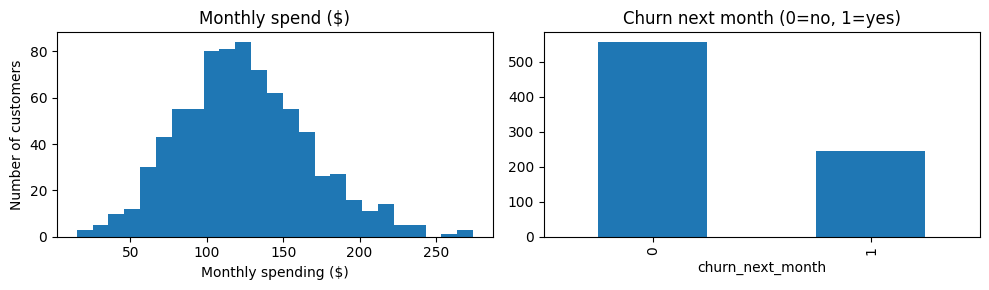

In [ ]:
# Display descriptive statistics
print(df.describe().round(2).to_string())

# Count missing values in the entire dataset
print('Missing values:', df.isna().sum().sum())

# Create one row with two charts
fig, ax = plt.subplots(1, 2, figsize=(10, 3))

# First chart: distribution of monthly spending
ax[0].hist(df.monthly_spend, bins=25)
ax[0].set_title('Monthly spend ($)')
ax[0].set_xlabel('Monthly spending ($)')
ax[0].set_ylabel('Number of customers')

# Second chart: number of customers who stayed or churned
churn_counts = df.churn_next_month.value_counts()
churn_counts = churn_counts.sort_index()

churn_counts.plot.bar(ax=ax[1])
ax[1].set_title('Churn next month (0=no, 1=yes)')

# Adjust spacing and display both charts
plt.tight_layout()
plt.show()

## 2. Linear Regression, forecast customer spending
**Business question:** What monthly spend should we expect given customer activity?

Use an 80/20 hold-out split. Report MAE, RMSE and R². Compare with a naive prediction of the training-set mean. The MAE is in dollars.


MAE $ 22.74
RMSE $ 27.45
R² 0.591
Mean baseline MAE $ 33.28


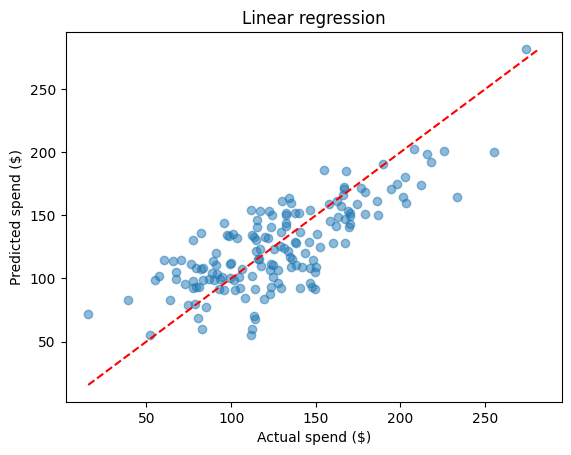

In [ ]:
# ============================================================
# STEP 7: LINEAR REGRESSION – PREDICT CUSTOMER SPENDING
# ============================================================

# Select the six customer characteristics used to predict spending
features = ['monthly_visits', 'orders_last_month', 'tenure_months',
            'days_since_last_order', 'discount_rate', 'support_tickets']

# X contains the input features (customer characteristics)
X = df[features]

# y contains the target variable we want to predict (monthly spending)
y_spend = df['monthly_spend']

# Split the dataset into 80% training data and 20% testing data
#We use 42 as a random seed so that every time we run the notebook, we get consistent results. It could be any integer. We're using the same number throughout the workshop for simplicity and reproducibility.
Xtr_r, Xte_r, ytr_r, yte_r = train_test_split(
    X, y_spend, test_size=.2, random_state=42
)

# Create and train a Linear Regression model using the training data
reg = LinearRegression().fit(Xtr_r, ytr_r)

# Predict monthly spending for the 20% of customers in the test set
pred_r = reg.predict(Xte_r)

# Calculate MAE: the average absolute difference between actual and predicted spending
print('MAE $', round(mean_absolute_error(yte_r, pred_r), 2))

# Calculate RMSE: similar to MAE but gives more weight to large prediction errors
print('RMSE $', round(np.sqrt(mean_squared_error(yte_r, pred_r)), 2))

# Calculate R²: how well the model explains variation in customer spending
print('R²', round(r2_score(yte_r, pred_r), 3))

# Compare against a simple baseline that predicts the training average for every customer
print('Mean baseline MAE $',
      round(mean_absolute_error(yte_r, np.full(len(yte_r), ytr_r.mean())), 2))

# Plot actual spending (X-axis) against predicted spending (Y-axis)
plt.scatter(yte_r, pred_r, alpha=.5)

# Find the lowest value across actual and predicted spending
low = min(yte_r.min(), pred_r.min())

# Find the highest value across actual and predicted spending
high = max(yte_r.max(), pred_r.max())

# Draw a red dashed reference line where predicted spending equals actual spending
plt.plot([low, high], [low, high], 'r--')
# Label the axes and chart
plt.xlabel('Actual spend ($)')
plt.ylabel('Predicted spend ($)')
plt.title('Linear regression')

# Display the chart
plt.show()

### Student challenge, write and run code
Build the reduced regression model with `monthly_visits` and `orders_last_month`. Compare MAE to the full model.

In [ ]:
# TODO: Fit reduced model and print its MAE


## 3. KNN, predict customer churn
**Business question:** Which customers may stop purchasing next month?

Create a **stratified** 80/20 split. Standardise features *inside* a pipeline. Evaluate accuracy, churn-class recall, precision, and the confusion matrix. Compare k=1,3,5,11,21 with five-fold stratified cross-validation **only on training data**. Select the best k before touching the test set.


CV recall (churn=1): [(1, np.float64(0.426)), (3, np.float64(0.395)), (5, np.float64(0.364)), (11, np.float64(0.308)), (21, np.float64(0.246))]
Chosen k: 1 Test accuracy: 0.6 Recall: 0.367 Precision: 0.353


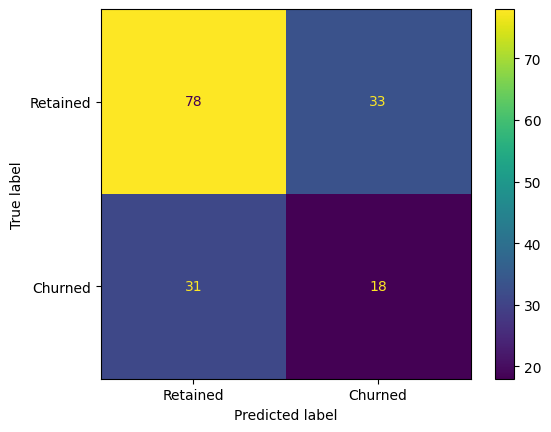

In [ ]:
# ============================================================
# STEP 8: KNN CLASSIFICATION – PREDICT CUSTOMER CHURN
# ============================================================

# Our target variable is churn:
# 0 = Customer stays (Retained), 1 = Customer leaves (Churned)
y_churn = df['churn_next_month']

# Split data into 80% training and 20% testing
# stratify ensures both sets have approximately the same proportion of churned customers
#So break the train and test with a equal proportion of churn customers (do not put many retained in test and many churned in train because the algorithm cannot do a good job then)
Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(
    X, y_churn, test_size=.2, random_state=42, stratify=y_churn
)

# Set up 5-fold cross-validation
# The training data is divided into 5 parts:
# Train on 4 parts and validate on 1, repeating 5 times
# StratifiedKFold maintains similar churn proportions in each part
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Try different numbers of neighbours to find the best KNN model
# For example, k=5 means using the 5 most similar customers to make a prediction
ks = [1, 3, 5, 11, 21]

# Create an empty list to store the results for each k
results = []

# Test each possible number of neighbours
for k in ks:

    # Create a pipeline that:
    # 1. Standardises customer features so distances are comparable
    # 2. Uses KNN to predict churn based on the nearest customers
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    # Evaluate the model using 5-fold cross-validation on the training data
    # Recall measures how many actual churners the model correctly identifies
    scores = cross_val_score(model, Xtr_c, ytr_c, cv=cv, scoring='recall')

    # Store the number of neighbours and its average recall across 5 folds
    results.append((k, scores.mean()))

# Display the average recall for each number of neighbours
print('CV recall (churn=1):', [(k, round(s, 3)) for k, s in results])

# Select the k with the highest average cross-validation recall
best_k = max(results, key=lambda item: item[1])[0]

# Create the final KNN model using the selected number of neighbours
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k)
)

# Train the final model using all the training data
knn.fit(Xtr_c, ytr_c)

# Predict whether customers in the test set will churn
pred_k = knn.predict(Xte_c)

# Evaluate the model on customers it has not seen during training
# Accuracy: percentage of all predictions that are correct
# Recall: percentage of actual churners correctly identified
# Precision: percentage of predicted churners who actually churned
print(
    'Chosen k:', best_k,
    'Test accuracy:', round(accuracy_score(yte_c, pred_k), 3),
    'Recall:', round(recall_score(yte_c, pred_k, zero_division=0), 3),
    'Precision:', round(precision_score(yte_c, pred_k, zero_division=0), 3)
)

# Display a confusion matrix comparing actual and predicted churn
# It shows correct predictions and the two types of classification mistakes
ConfusionMatrixDisplay.from_predictions(
    yte_c, pred_k, display_labels=['Retained', 'Churned']
)
plt.show()

### Student challenge
Build a simpler KNN model using only three features

In [ ]:
# TODO: build a simpler KNN model using only three features:
#days_since_last_order
#orders_last_month
#support_tickets

#Which model does a better job?

## 4. Decision Tree, explain churn patterns
**Business question:** Which observable patterns help predict churn?

Tune maximum depth using training-only cross-validation. Compare training and CV performance; then evaluate the selected tree once on the test set. Visualise the tree and identify the first split.


 depth  training_accuracy  cv_accuracy
     1              0.695        0.677
     2              0.727        0.697
     3              0.731        0.694
     4              0.761        0.695
     6              0.794        0.708
    10              0.806        0.695
Selected depth: 6 Test accuracy: 0.694 Churn recall: 0.306


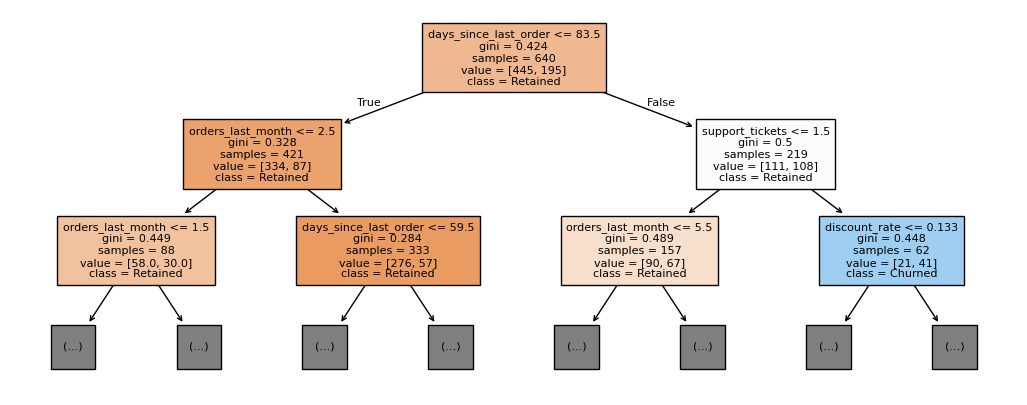

In [ ]:
# ============================================================
# STEP 9: DECISION TREE – PREDICT CUSTOMER CHURN
# ============================================================

# A Decision Tree predicts churn by learning decision rules.
# For example: If a customer hasn't ordered for 90 days,
# are they more likely to leave the business?

# Try different tree depths (maximum number of decision levels)
# A shallow tree is simpler; a deeper tree can learn more complex rules
depths = [1, 2, 3, 4, 6, 10]

# Create an empty list to store the results
tree_scores = []

# Test each tree depth to find the best model
for depth in depths:

    # Create a Decision Tree with the current maximum depth
    # min_samples_leaf=10 means each final group must contain at least 10 customers
    # This helps prevent the tree from learning overly specific rules
    candidate = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=10,
        random_state=42
    )

    # Train the tree using the training customers
    candidate.fit(Xtr_c, ytr_c)

    # Calculate accuracy on the same customers used for training
    train_acc = accuracy_score(ytr_c, candidate.predict(Xtr_c))

    # Calculate average accuracy using 5-fold cross-validation
    # This helps us assess how well the tree performs on unseen data
    cv_acc = cross_val_score(
        candidate, Xtr_c, ytr_c, cv=cv, scoring='accuracy'
    ).mean()

    # Save the depth, training accuracy and cross-validation accuracy
    tree_scores.append((depth, train_acc, cv_acc))

# Display the results for different tree depths
# Comparing training and CV accuracy helps us identify possible overfitting
print(
    pd.DataFrame(
        tree_scores,
        columns=['depth', 'training_accuracy', 'cv_accuracy']
    ).round(3).to_string(index=False)
)

# Select the depth with the highest cross-validation accuracy
best_depth = max(tree_scores, key=lambda row: row[2])[0]

# Create and train the final Decision Tree using the selected depth
tree = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_leaf=10,
    random_state=42
).fit(Xtr_c, ytr_c)

# Predict churn for customers in the test set
pred_t = tree.predict(Xte_c)

# Evaluate the final model on unseen customers
# Accuracy: percentage of all customers classified correctly
# Recall: percentage of actual churners correctly identified
print(
    'Selected depth:', best_depth,
    'Test accuracy:', round(accuracy_score(yte_c, pred_t), 3),
    'Churn recall:', round(recall_score(yte_c, pred_t, zero_division=0), 3)
)

# Create a figure for displaying the Decision Tree
plt.figure(figsize=(13, 5))

# Visualise the tree and its decision rules
# feature_names: display customer characteristics at each decision
# class_names: show whether customers are predicted to stay or churn
# filled=True: colour the nodes based on their predicted class
# max_depth=2: display only the first two levels of decisions
# fontsize=8: control the text size
plot_tree(
    tree,
    feature_names=features,
    class_names=['Retained', 'Churned'],
    filled=True,
    max_depth=2,
    fontsize=8
)

# Display the Decision Tree
plt.show()

### Student challenge
Change the maximum tree depth

In [ ]:
# TODO: change the maximum tree depth to 2,4, 10. compare the training and testing accuracy and see how you can interprete this?

## 5. K-Means, segment customers
**Business question:** Are there groups of customers with different activity profiles?

K-Means sees **only predictor features**, not spend or churn labels. Standardise predictors; test k=2 to 6 with silhouette scores. Fit the best k and profile each cluster by averages.

Silhouette scores: [(2, np.float64(0.135)), (3, np.float64(0.125)), (4, np.float64(0.136)), (5, np.float64(0.131)), (6, np.float64(0.134))]
Selected clusters: 4
         monthly_visits  orders_last_month  tenure_months  days_since_last_order  discount_rate  support_tickets  monthly_spend  churn_next_month
segment                                                                                                                                          
0                  9.08               3.11          47.41                  59.94           0.22             0.74         115.10              0.28
1                 11.79               6.05          35.01                  54.98           0.14             0.83         167.77              0.20
2                  9.02               3.53          29.89                  51.89           0.15             2.61         116.67              0.36
3                  9.88               3.74          13.67                  74.24           0.24             0

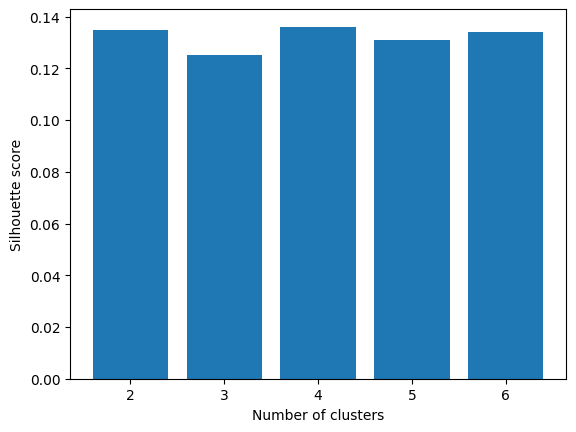

In [ ]:
# ============================================================
# STEP 10: K-MEANS CLUSTERING – CUSTOMER SEGMENTATION
# ============================================================

# K-Means groups customers based on similarities in their behaviour.
# Unlike previous models, we do not tell K-Means who churned or how much they spent.
# Instead, it discovers groups of customers with similar characteristics.

# Select the six customer characteristics used to create the groups
cluster_features = [
    'monthly_visits',
    'orders_last_month',
    'tenure_months',
    'days_since_last_order',
    'discount_rate',
    'support_tickets'
]

# Create a scaler to standardise the customer characteristics
# This is important because K-Means groups customers based on distances
scaler = StandardScaler()

# Standardise the features so differences in numerical scales do not dominate
# Z contains the standardised information for all 800 customers
Z = scaler.fit_transform(df[cluster_features])

# Create an empty list to store the evaluation scores
sil = []

# Try dividing customers into 2, 3, 4, 5 and 6 groups
# We want to find a suitable number of customer segments
for k in range(2, 7):

    # Run K-Means with the current number of clusters
    # n_clusters=k: divide customers into k groups
    # n_init=10: try 10 different initial starting points and keep the best result
    # fit_predict: find the groups and assign each customer a cluster number
    labels = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    ).fit_predict(Z)

    # Calculate the silhouette score to evaluate the clustering
    # A higher score means customers are generally closer to their own group
    # and further away from other groups
    # Save both the number of clusters and its silhouette score
    sil.append((k, silhouette_score(Z, labels)))

# Display the silhouette score for each number of clusters
print('Silhouette scores:', [(k, round(v, 3)) for k, v in sil])

# Select the number of clusters with the highest silhouette score
best_clusters = max(sil, key=lambda item: item[1])[0]

# Run the final K-Means model using the selected number of clusters
# Each customer receives a cluster label such as 0, 1 or 2
clusters = KMeans(
    n_clusters=best_clusters,
    random_state=42,
    n_init=10
).fit_predict(Z)

# Create a copy of the original dataset
profile = df.copy()

# Add a new column showing which segment each customer belongs to
profile['segment'] = clusters

# Display the selected number of customer segments
print('Selected clusters:', best_clusters)

# Calculate the average characteristics of customers in each segment
# This helps us understand how the groups differ from each other
# We also examine average spending and churn, although these were
# NOT used by K-Means to create the groups
# Because churn is 0 or 1, its average represents the segment's churn rate
print(
    profile.groupby('segment')[
        cluster_features + ['monthly_spend', 'churn_next_month']
    ].mean().round(2).to_string()
)

# Create a bar chart comparing silhouette scores for different K values
# The tallest bar represents the best score among the options tested
plt.bar([k for k, v in sil], [v for k, v in sil])

# Label the axes
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')

# Display the chart
plt.show()



### Student challenge
Show segment sizes

In [ ]:
#Suggest names for segments
# TODO: Show segment sizes

## 6. Final challenge, 10-minute business decision


Final workshop question
Imagine you're a data analyst working for an online retail company. Your manager asks you three questions:

1- How much will a customer spend next month? Which machine learning technique would you use?

2- Which customers are likely to stop shopping with us? Which technique would you use?

3- Can we divide our customers into groups with similar shopping behaviours? Which technique would you use?
